### Task 1: Features and Labels

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [10]:
df = pd.read_csv("spotify.csv", encoding="latin1")

# Convert column names to lowercase
df.columns = df.columns.str.strip().str.lower()

print("First 5 Rows:")
display(df.head())

print("Dataset Shape:", df.shape)

First 5 Rows:


,unnamed: 0,track.name,artist.name,genre,beats.per.minute,energy,danceability,loudness..db..,liveness,valence.,length.,acousticness..,speechiness.,popularity
0,1,Señorita,Shawn Mendes,canadian pop,117,55,76,-6,8,75,191,4,3,79
1,2,China,Anuel AA,reggaeton flow,105,81,79,-4,8,61,302,8,9,92
2,3,boyfriend (with Social House),Ariana Grande,dance pop,190,80,40,-4,16,70,186,12,46,85
3,4,Beautiful People (feat. Khalid),Ed Sheeran,pop,93,65,64,-8,8,55,198,12,19,86
4,5,Goodbyes (Feat. Young Thug),Post Malone,dfw rap,150,65,58,-4,11,18,175,45,7,94


Dataset Shape: (50, 14)


In [11]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (50, 14)

Column Names:
['unnamed: 0', 'track.name', 'artist.name', 'genre', 'beats.per.minute', 'energy', 'danceability', 'loudness..db..', 'liveness', 'valence.', 'length.', 'acousticness..', 'speechiness.', 'popularity']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   unnamed: 0        50 non-null     int64 
 1   track.name        50 non-null     object
 2   artist.name       50 non-null     object
 3   genre             50 non-null     object
 4   beats.per.minute  50 non-null     int64 
 5   energy            50 non-null     int64 
 6   danceability      50 non-null     int64 
 7   loudness..db..    50 non-null     int64 
 8   liveness          50 non-null     int64 
 9   valence.          50 non-null     int64 
 10  length.           50 non-null     int64 
 11  acousticness..    50 non-null    

In [12]:
# Select label
label = "popularity"

# Select numerical features
features = df.select_dtypes(include=np.number).columns.tolist()

# Remove label from features
features.remove(label)

print("Features (X):")
print(features)

print("\nLabel (y):")
print(label)

Features (X):
['unnamed: 0', 'beats.per.minute', 'energy', 'danceability', 'loudness..db..', 'liveness', 'valence.', 'length.', 'acousticness..', 'speechiness.']

Label (y):
popularity


### Task 2 – Split Dataset into Training and Testing Sets

In [13]:
from sklearn.model_selection import train_test_split

# Select features and label
X = df[features]
y = df[label]

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Print number of rows
print("Total Rows:", len(df))
print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))

Total Rows: 50
Training Rows: 40
Testing Rows: 10


### Task 3 – Underfitting and Overfitting

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Select input and output columns
X = df[["danceability"]]
y = df["popularity"]

# Remove missing values
data = pd.concat([X, y], axis=1).dropna()

X = data[["danceability"]]
y = data["popularity"]

# Split data: 5% training and 95% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.05, random_state=42
)

# Create and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
train_prediction = model.predict(X_train)
test_prediction = model.predict(X_test)

# Check model performance
print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))

print("\nTraining MAE:",
      mean_absolute_error(y_train, train_prediction))

print("Testing MAE:",
      mean_absolute_error(y_test, test_prediction))

print("\nTesting R2 Score:",
      r2_score(y_test, test_prediction))

Training Rows: 2
Testing Rows: 48

Training MAE: 1.4210854715202004e-14
Testing MAE: 10.377083333333326

Testing R2 Score: -11.01606016672706


### Task 4 – Bias-Variance Tradeoff

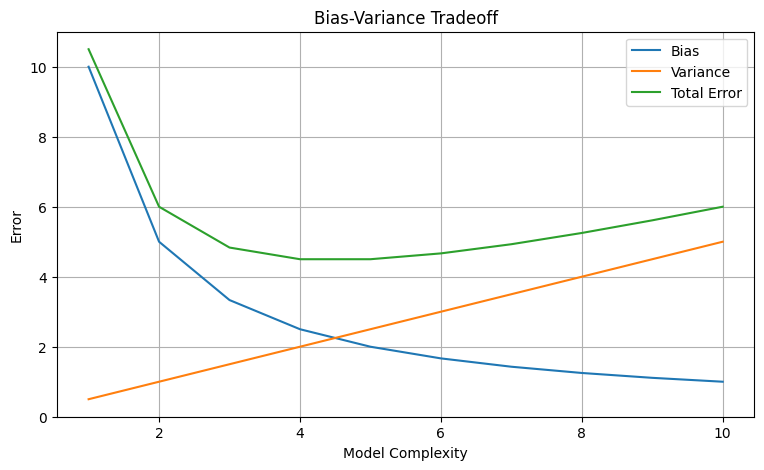

In [17]:
import numpy as np
import matplotlib.pyplot as plt

model_complexity = np.arange(1, 11)

bias = 10 / model_complexity
variance = model_complexity * 0.5
total_error = bias + variance

plt.figure(figsize=(9, 5))

plt.plot(model_complexity, bias, label="Bias")
plt.plot(model_complexity, variance, label="Variance")
plt.plot(model_complexity, total_error, label="Total Error")

plt.xlabel("Model Complexity")
plt.ylabel("Error")
plt.title("Bias-Variance Tradeoff")

plt.legend()
plt.grid(True)

plt.show()

### Task 5: Real-Life Example of Overfitting

Example: Instagram

Instagram may show similar posts repeatedly based on my previous likes and views. If its recommendation model learns too much from my limited activity, it may keep recommending only similar content and ignore my other interests.

This is an example of overfitting because the model focuses too much on previous user activity and may not perform well when my interests change.